# Trial mode: multiple linear regression and backward reduction

Read the raw household workbook into an unchanged source frame, create a working copy, exclude recorded vehicles **>=10** and dwelling code **9 (Unknown)**, then use one fixed estimation sample for every comparison. This implements the discussed vehicle cutoff, including the previously approved 99-vehicle household. The guide records 99 numerically: this exclusion is an analytical outlier policy, not a missing-code interpretation.

Five justified starting specifications are reduced using three separate rules: **p < 0.01**, AIC, and BIC. The primary trial model is the lowest-BIC terminal model among the p-value reduction paths. AIC/BIC-only paths are exploratory comparisons and need not satisfy the p-value rule. This is an exploratory search, not proof of a uniquely best model. All evaluation is **in-sample**, with no training/test partition.

Estimation is unweighted ordinary least squares. Primary tests and intervals use covariance clustered by residential traffic zone. AIC/BIC are working Gaussian OLS criteria on identical observations; clustered covariance does not turn them into a full survey or correlated-error likelihood. Expansion factors are used only for labeled evaluation/zone expansion. Original data, the existing EDA notebook, and historical split files are not modified.

In [1]:
from pathlib import Path
from collections import OrderedDict
from importlib.metadata import version
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence
from IPython.display import display, Image

BASE_DIR = Path.cwd()
WORKBOOK = BASE_DIR / 'inputs' / 'households.xlsx'
SHEET = '2006-hhld'
WORK = BASE_DIR / 'intermediaries' / 'trial_mode'
OUTPUT = BASE_DIR / 'final_outputs' / 'trial_mode'
TABLES = OUTPUT / 'tables'
FIGURES = OUTPUT / 'figures'
for folder in [WORK, OUTPUT, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

ALPHA = 0.01
HIGH_VEHICLE_CUTOFF = 10
PROTECTED_EFFECTS = {'size'}
IC_IMPROVEMENT_TOLERANCE = 1e-8
FIELDS = ['hnum', 'gta01hhld', 'dwelltype', 'rec-mail', 'n-call', 'tripday',
          'nperson', 'nvehicle', 'nlicence', 'nempft', 'nemppt', 'nemphome',
          'nstudent', 'nhhldtrip', 'expf']
REGION_RANGES = {'Toronto': (1, 481), 'Durham': (501, 765),
                 'York': (1001, 1353), 'Peel': (1501, 1753)}
SOURCE_SHA256 = hashlib.sha256(WORKBOOK.read_bytes()).hexdigest()
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)

def format_pvalue(value):
    if pd.isna(value):
        return ''
    if value < 1e-300:
        return '<1e-300'
    return f'{value:.3g}' if value < 1e-4 else f'{value:.5f}'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': '#FAFCFF',
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, TEAL = '#2563EB', '#E99416', '#0F9C91'

def save_table(name, frame):
    frame.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig',
                 lineterminator='\n', float_format='%.12g')
    return frame

def save_figure(fig, name):
    path = FIGURES / f'{name}.png'
    fig.savefig(path, dpi=220, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path), width=1100))

environment = pd.DataFrame([{'package': p, 'version': version(p)} for p in
    ['numpy', 'pandas', 'openpyxl', 'matplotlib', 'scipy', 'statsmodels', 'ipython']])
save_table('TM00_environment', environment)
display(environment)

,package,version
0,numpy,2.4.6
1,pandas,3.0.3
2,openpyxl,3.1.5
3,matplotlib,3.10.9
4,scipy,1.18.0
5,statsmodels,0.14.6
6,ipython,9.14.0


## 1. Raw data, working copy, and transparent exclusions

Only columns B:P are analytical source fields. Dwelling code 9 is explicitly Unknown; vehicle values 0-99 are numeric in the source guide. The present exclusion removes the upper vehicle tail by instruction. Unknown advance-letter responses, zero trips, and overlapping worker/student statuses are not independent deletion criteria. Home workers are already included in full-/part-time worker counts.

The outcome is recorded person trips per household for one surveyed weekday (ages 11+). Household size includes younger residents, and student counts include assumed students aged 6-10; interpret composition coefficients with that coverage difference in mind.

In [2]:
raw = pd.read_excel(WORKBOOK, sheet_name=SHEET, usecols='B:P', dtype=object, engine='openpyxl')
assert raw.columns.tolist() == FIELDS
raw_fingerprint = pd.util.hash_pandas_object(raw, index=True).to_numpy().copy()
working = raw.copy(deep=True)
working.insert(0, 'source_excel_row', np.arange(len(working)) + 2)

for field in FIELDS:
    if field != 'rec-mail':
        working[field] = pd.to_numeric(working[field], errors='raise')
        assert np.isfinite(working[field]).all(), f'Nonfinite {field}'
        if field != 'expf':
            assert working[field].mod(1).eq(0).all(), f'Noninteger {field}'
            working[field] = working[field].astype('int64')
assert working['hnum'].is_unique
assert working['dwelltype'].isin([1, 2, 3, 9]).all()
assert working['tripday'].isin([1, 2, 3, 4, 5]).all()
assert working['nperson'].between(1, 99).all()
assert working['nvehicle'].between(0, 99).all()
assert working['nhhldtrip'].between(0, 99).all()
for field in ['nlicence', 'nempft', 'nemppt', 'nemphome', 'nstudent']:
    assert working[field].between(0, 9).all(), field
assert working['expf'].gt(0).all()
assert working['nlicence'].le(working['nperson']).all()
assert (working['nempft'] + working['nemppt']).le(working['nperson']).all()
assert working['nemphome'].le(working['nempft'] + working['nemppt']).all()
assert working['nstudent'].le(working['nperson']).all()

working['excluded_high_vehicle'] = working['nvehicle'].ge(HIGH_VEHICLE_CUTOFF)
working['excluded_unknown_dwelling'] = working['dwelltype'].eq(9)
excluded_mask = working['excluded_high_vehicle'] | working['excluded_unknown_dwelling']
excluded = working.loc[excluded_mask].copy()
excluded['exclusion_reason'] = [
    '; '.join(reason for flag, reason in [(v, 'vehicles >=10'), (d, 'dwelling code 9 Unknown')] if flag)
    for v, d in zip(excluded['excluded_high_vehicle'], excluded['excluded_unknown_dwelling'])]
excluded.to_csv(WORK / 'excluded_households.csv', index=False, encoding='utf-8-sig')
trial = working.loc[~excluded_mask].copy().reset_index(drop=True)
trial['workers'] = trial['nempft'] + trial['nemppt']
trial['dwelling'] = trial['dwelltype'].map({1: 'House', 2: 'Apartment', 3: 'Townhouse'})
trial['weekday'] = trial['tripday'].map(dict(enumerate(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], start=1)))
trial['region'] = ''
for region, (low, high) in REGION_RANGES.items():
    trial.loc[trial['gta01hhld'].between(low, high), 'region'] = region
assert trial['region'].ne('').all()
assert len(trial) + len(excluded) == len(raw)
assert trial['nvehicle'].lt(HIGH_VEHICLE_CUTOFF).all() and trial['dwelltype'].ne(9).all()
assert np.array_equal(pd.util.hash_pandas_object(raw, index=True), raw_fingerprint)
trial.to_csv(WORK / 'households_trial.csv', index=False, encoding='utf-8-sig', float_format='%.15g')

sample_flow = pd.DataFrame([
    {'stage_or_issue': 'Raw supplied households', 'households': len(raw)},
    {'stage_or_issue': 'Vehicles >=10', 'households': int(working['excluded_high_vehicle'].sum())},
    {'stage_or_issue': 'Dwelling code 9 Unknown', 'households': int(working['excluded_unknown_dwelling'].sum())},
    {'stage_or_issue': 'Overlap of the two exclusion reasons', 'households': int((working['excluded_high_vehicle'] & working['excluded_unknown_dwelling']).sum())},
    {'stage_or_issue': 'Unique excluded households', 'households': len(excluded)},
    {'stage_or_issue': 'Fixed estimation sample for every trial model', 'households': len(trial)},
    {'stage_or_issue': 'Zero-trip households retained in estimation', 'households': int(trial['nhhldtrip'].eq(0).sum())},
    {'stage_or_issue': 'Residential zones represented', 'households': trial['gta01hhld'].nunique()},
])
save_table('TM01_sample_flow', sample_flow)
exclusion_dwelling = excluded.assign(dwelling=excluded['dwelltype'].map(
    {1: 'House', 2: 'Apartment', 3: 'Townhouse', 9: 'Unknown'})).groupby(
    ['excluded_high_vehicle', 'excluded_unknown_dwelling', 'dwelling']).size().reset_index(name='households')
save_table('TM02_exclusion_dwelling', exclusion_dwelling)
display(sample_flow)
display(exclusion_dwelling)

,stage_or_issue,households
0,Raw supplied households,93307
1,Vehicles >=10,33
2,Dwelling code 9 Unknown,9
3,Overlap of the two exclusion reasons,0
4,Unique excluded households,42
5,Fixed estimation sample for every trial model,93265
6,Zero-trip households retained in estimation,10474
7,Residential zones represented,1179


,excluded_high_vehicle,excluded_unknown_dwelling,dwelling,households
0,False,True,Unknown,9
1,True,False,Apartment,3
2,True,False,House,27
3,True,False,Townhouse,3


## 2. Candidate effects, categories, and model families

House, Monday, and Toronto are categorical references. Each factor is added/removed as one whole effect, even when it has multiple indicator columns. Numeric variables retain exact counts. Size is centered at 3 residents, vehicles at 1, and licensed drivers at 2. Centering changes coefficient references without changing the linear model's fitted values. Curvature and interaction interpretations depend on these centers.

Household size is protected as the substantive core predictor. Interaction parents and lower-order terms supporting retained quadratics are also protected by hierarchy. Separate full-/part-time worker counts and their total are alternative specifications, never simultaneous regressors. IDs, survey-process fields, expansion factors, and arbitrary display categories are not candidate regressors.

In [3]:
features = pd.DataFrame(index=trial.index)
features['size_c'] = trial['nperson'] - 3
features['vehicles_c'] = trial['nvehicle'] - 1
features['drivers_c'] = trial['nlicence'] - 2
for name, field in [('full_time', 'nempft'), ('part_time', 'nemppt'),
                    ('home_workers', 'nemphome'), ('students', 'nstudent'), ('workers', 'workers')]:
    features[name] = trial[field].astype(float)
features['size_c_squared'] = features['size_c'] ** 2
features['vehicles_c_squared'] = features['vehicles_c'] ** 2
features['size_x_drivers'] = features['size_c'] * features['drivers_c']
features['size_x_vehicles'] = features['size_c'] * features['vehicles_c']
CATEGORY_LEVELS = OrderedDict([
    ('dwelling', ['House', 'Apartment', 'Townhouse']),
    ('weekday', ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']),
    ('region', ['Toronto', 'Durham', 'York', 'Peel']),
])
for field, levels in CATEGORY_LEVELS.items():
    assert trial[field].isin(levels).all()
    for level in levels[1:]:
        features[f'{field}_{level}'] = trial[field].eq(level).astype(float)
features = features.astype(float)

EFFECT_COLUMNS = OrderedDict([
    ('size', ['size_c']), ('vehicles', ['vehicles_c']), ('drivers', ['drivers_c']),
    ('full_time', ['full_time']), ('part_time', ['part_time']), ('workers', ['workers']),
    ('home_workers', ['home_workers']), ('students', ['students']),
    ('dwelling', ['dwelling_Apartment', 'dwelling_Townhouse']),
    ('weekday', [f'weekday_{x}' for x in CATEGORY_LEVELS['weekday'][1:]]),
    ('region', [f'region_{x}' for x in CATEGORY_LEVELS['region'][1:]]),
    ('size_squared', ['size_c_squared']), ('vehicles_squared', ['vehicles_c_squared']),
    ('size_by_drivers', ['size_x_drivers']), ('size_by_vehicles', ['size_x_vehicles']),
])
PARENTS = {'size_squared': {'size'}, 'vehicles_squared': {'vehicles'},
           'size_by_drivers': {'size', 'drivers'}, 'size_by_vehicles': {'size', 'vehicles'}}
SEPARATE_MAIN = ['size', 'vehicles', 'drivers', 'full_time', 'part_time',
                 'home_workers', 'students', 'dwelling', 'weekday', 'region']
FAMILIES = OrderedDict([
    ('Separate employment main effects', SEPARATE_MAIN),
    ('Total workers main effects', ['size', 'vehicles', 'drivers', 'workers',
                                   'home_workers', 'students', 'dwelling', 'weekday', 'region']),
    ('Size and vehicle curvature', SEPARATE_MAIN + ['size_squared', 'vehicles_squared']),
    ('Size by licensed drivers', SEPARATE_MAIN + ['size_by_drivers']),
    ('Size by vehicles', SEPARATE_MAIN + ['size_by_vehicles']),
])

def canonical(effects):
    return tuple(e for e in EFFECT_COLUMNS if e in effects)

def validate_effects(effects):
    assert set(effects) <= set(EFFECT_COLUMNS)
    assert not ('workers' in effects and ('full_time' in effects or 'part_time' in effects))
    for effect in effects:
        assert PARENTS.get(effect, set()) <= set(effects), f'Hierarchy broken: {effect}'

candidate_families = pd.DataFrame([
    {'family': name, 'starting_effects': ' + '.join(canonical(effects)),
     'starting_parameters_including_intercept': 1 + sum(len(EFFECT_COLUMNS[e]) for e in effects)}
    for name, effects in FAMILIES.items()])
save_table('TM03_candidate_families', candidate_families)
display(candidate_families)
y = trial['nhhldtrip'].to_numpy(dtype=float)
zones = trial['gta01hhld'].to_numpy()
weights = trial['expf'].to_numpy(dtype=float)
N = len(y)
N_ZONES = len(np.unique(zones))
row_id_hash = hashlib.sha256(trial['hnum'].to_numpy(dtype='<i8').tobytes()).hexdigest()

,family,starting_effects,starting_parameters_including_intercept
0,Separate employment main effects,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,17
1,Total workers main effects,size + vehicles + drivers + workers + home_workers + students + dwelling + weekday + region,16
2,Size and vehicle curvature,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,19
3,Size by licensed drivers,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,18
4,Size by vehicles,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,18


## 3. Fitting and whole-effect tests

Every model uses precisely the same households and unweighted OLS. Primary whole-effect tests are zone-clustered Wald F tests, allowing dependence within traffic zones and heteroskedasticity. Classical independent-error partial F p-values are recorded alongside them for comparison. These choices are explicit because a textbook p-value assumes an error structure; changing covariance changes tests, not the OLS point estimates.

AIC and BIC use the same Gaussian OLS likelihood convention and response observations in all models. They are useful working comparison criteria, not a correction for adaptive selection or a certificate of out-of-sample accuracy. Model results are cached as compact statistics, not large fitted objects.

In [4]:
MODEL_CACHE = {}

def build_matrix(effects):
    effects = canonical(effects)
    validate_effects(effects)
    columns = ['Intercept'] + [col for effect in effects for col in EFFECT_COLUMNS[effect]]
    x = np.column_stack([np.ones(N), features[columns[1:]].to_numpy(dtype=float)])
    return x, columns

def materialize(effects):
    x, columns = build_matrix(effects)
    fit = sm.OLS(y, x, missing='raise').fit()
    assert fit.nobs == N and fit.model.rank == len(columns)
    clustered = fit.get_robustcov_results(cov_type='cluster', groups=zones,
        use_correction=True, df_correction=True, use_t=True)
    assert clustered.df_resid_inference == N_ZONES - 1
    return fit, clustered, columns

def effect_tests(fit, clustered, columns, effects):
    rows = []
    for effect in canonical(effects):
        indices = [columns.index(c) for c in EFFECT_COLUMNS[effect]]
        restrictions = np.eye(len(columns))[indices]
        robust_test = clustered.f_test(restrictions)
        classical_test = fit.f_test(restrictions)
        rows.append({'effect': effect, 'df_effect': len(indices),
                     'clustered_F': float(np.asarray(robust_test.fvalue).item()),
                     'p_clustered': float(np.asarray(robust_test.pvalue).item()),
                     'p_classical': float(np.asarray(classical_test.pvalue).item()),
                     'df_cluster_denominator': float(robust_test.df_denom)})
    return rows

def evaluate(effects):
    key = canonical(effects)
    if key in MODEL_CACHE:
        return MODEL_CACHE[key]
    fit, clustered, columns = materialize(key)
    prediction = np.asarray(fit.fittedvalues)
    error = prediction - y
    summary = {'n': N, 'n_zones': N_ZONES, 'parameters': len(columns),
               'aic': float(fit.aic), 'bic': float(fit.bic),
               'r_squared': float(fit.rsquared), 'adjusted_r_squared': float(fit.rsquared_adj),
               'rmse_in_sample': float(np.sqrt(np.mean(error ** 2))),
               'mae_in_sample': float(np.mean(np.abs(error))),
               'mean_prediction_error_pred_minus_obs': float(error.mean()),
               'residual_standard_error': float(np.sqrt(fit.mse_resid)),
               'negative_predictions_n': int((prediction < 0).sum()),
               'minimum_prediction': float(prediction.min()),
               'maximum_prediction': float(prediction.max())}
    info = {'effects': key, 'columns': columns, 'stats': summary,
            'effect_tests': effect_tests(fit, clustered, columns, key)}
    MODEL_CACHE[key] = info
    return info

def removal_status(effect, effects):
    if effect in PROTECTED_EFFECTS:
        return False, 'Prespecified substantive core'
    children = [child for child in effects if effect in PARENTS.get(child, set())]
    if children:
        return False, 'Required by hierarchy: ' + ', '.join(children)
    return True, 'Eligible for removal'

## 4. Iterative backward reduction: p < 0.01, AIC, and BIC

For p-value reduction, remove the removable effect with the highest clustered joint p-value while it is **>=0.01**, refit, and reassess. Retained categorical levels are assessed jointly, so an individual indicator can have p>=0.01 while its factor remains significant. Protected core/hierarchy terms may remain regardless of their own p-value.

The separate AIC/BIC searches remove the eligible effect that most improves the respective criterion, stopping when no one-effect deletion improves it. Those searches are not required to meet p<0.01. All searches are backward/greedy within their stated starting family; they are not exhaustive searches of every possible transformation, interaction, or subset.

In [5]:
path_rows, effect_path_rows, candidate_drop_rows, terminal_rows = [], [], [], []

def backward_reduce(family, start, rule):
    current = canonical(start)
    step = 0
    while True:
        info = evaluate(current)
        tests = {r['effect']: r for r in info['effect_tests']}
        eligible = []
        for effect in current:
            can_drop, reason = removal_status(effect, current)
            effect_path_rows.append({'family': family, 'rule': rule, 'step': step,
                                    **tests[effect], 'can_drop': can_drop, 'retention_status': reason})
            if can_drop:
                eligible.append(effect)
        drop, improvement = None, np.nan
        if rule == 'p01':
            failures = [e for e in eligible if tests[e]['p_clustered'] >= ALPHA]
            if failures:
                drop = max(failures, key=lambda e: (tests[e]['p_clustered'], e))
        else:
            scored = []
            for effect in eligible:
                reduced = evaluate([e for e in current if e != effect])
                delta = info['stats'][rule] - reduced['stats'][rule]
                scored.append((reduced['stats'][rule], effect, delta))
                candidate_drop_rows.append({'family': family, 'rule': rule, 'step': step,
                    'candidate_drop': effect, 'current_criterion': info['stats'][rule],
                    'reduced_criterion': reduced['stats'][rule], 'improvement': delta,
                    'current_effect_p_clustered': tests[effect]['p_clustered'], 'n': N,
                    'current_effects': ' + '.join(current)})
            if scored:
                _, proposed, delta = min(scored)
                if delta > IC_IMPROVEMENT_TOLERANCE:
                    drop, improvement = proposed, delta
        path_rows.append({'family': family, 'rule': rule, 'step': step,
            'effects': ' + '.join(current), 'action': 'stop' if drop is None else 'remove',
            'dropped_effect': '' if drop is None else drop,
            'dropped_effect_p_clustered': np.nan if drop is None else tests[drop]['p_clustered'],
            'criterion_improvement': improvement, **info['stats']})
        if drop is None:
            break
        assert removal_status(drop, current)[0]
        if rule == 'p01':
            assert tests[drop]['p_clustered'] >= ALPHA
        else:
            assert improvement > IC_IMPROVEMENT_TOLERANCE
        current = canonical([e for e in current if e != drop])
        step += 1
    eligible_p = [r['p_clustered'] for r in info['effect_tests'] if removal_status(r['effect'], current)[0]]
    satisfies_alpha = all(p < ALPHA for p in eligible_p)
    if rule == 'p01':
        assert satisfies_alpha
    terminal_rows.append({'family': family, 'rule': rule, 'steps_removed': step,
        'effects': ' + '.join(current), 'effect_count': len(current),
        'p01_satisfied_for_removable_effects': satisfies_alpha,
        'row_id_sha256': row_id_hash, **info['stats']})
    return current

terminal_effects = {}
started = time.monotonic()
for family, start in FAMILIES.items():
    for rule in ['p01', 'aic', 'bic']:
        terminal_effects[(family, rule)] = backward_reduce(family, start, rule)
        print(f'{family} / {rule}: retained {len(terminal_effects[(family, rule)])} effects', flush=True)

paths = save_table('TM04_backward_paths', pd.DataFrame(path_rows))
effect_paths = save_table('TM05_effect_tests_by_step', pd.DataFrame(effect_path_rows))
drop_candidates = save_table('TM06_information_criterion_drop_checks', pd.DataFrame(candidate_drop_rows))
comparison = pd.DataFrame(terminal_rows)
comparison['delta_bic_all_terminal_models'] = comparison['bic'] - comparison['bic'].min()
comparison['delta_aic_all_terminal_models'] = comparison['aic'] - comparison['aic'].min()
shortlist = comparison.loc[comparison['rule'].eq('p01')].sort_values(['bic', 'parameters', 'family'])
chosen_row = shortlist.iloc[0]
chosen_family = chosen_row['family']
chosen_effects = terminal_effects[(chosen_family, 'p01')]
comparison['selected_primary_trial'] = comparison['family'].eq(chosen_family) & comparison['rule'].eq('p01')
comparison = comparison.sort_values(['bic', 'parameters', 'family', 'rule']).reset_index(drop=True)
save_table('TM07_terminal_model_comparison', comparison)
display(comparison[['family', 'rule', 'steps_removed', 'parameters', 'adjusted_r_squared',
                    'rmse_in_sample', 'mae_in_sample', 'aic', 'bic',
                    'p01_satisfied_for_removable_effects', 'selected_primary_trial']].round(4))
print(f'{len(MODEL_CACHE)} unique predictor designs evaluated in {time.monotonic() - started:.1f}s.')
print('Primary trial:', chosen_family, '| retained:', ' + '.join(chosen_effects))
display(paths.loc[paths['rule'].eq('p01'), ['family', 'step', 'action', 'dropped_effect',
    'dropped_effect_p_clustered', 'parameters', 'aic', 'bic']].round(5))

Separate employment main effects / p01: retained 9 effects
Separate employment main effects / aic: retained 10 effects
Separate employment main effects / bic: retained 9 effects
Total workers main effects / p01: retained 8 effects
Total workers main effects / aic: retained 9 effects
Total workers main effects / bic: retained 8 effects
Size and vehicle curvature / p01: retained 11 effects
Size and vehicle curvature / aic: retained 12 effects
Size and vehicle curvature / bic: retained 11 effects
Size by licensed drivers / p01: retained 9 effects
Size by licensed drivers / aic: retained 11 effects
Size by licensed drivers / bic: retained 9 effects
Size by vehicles / p01: retained 9 effects
Size by vehicles / aic: retained 10 effects
Size by vehicles / bic: retained 9 effects
86 unique predictor designs evaluated in 6.2s.
Primary trial: Size and vehicle curvature | retained: size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday + size_squared + ve

,family,rule,steps_removed,parameters,adjusted_r_squared,rmse_in_sample,mae_in_sample,aic,bic,p01_satisfied_for_removable_effects,selected_primary_trial
0,Size and vehicle curvature,bic,1,16,0.4646,3.3381,2.3903,489548.4573,489699.5485,True,False
1,Size and vehicle curvature,p01,1,16,0.4646,3.3381,2.3903,489548.4573,489699.5485,True,True
2,Size and vehicle curvature,aic,0,19,0.4647,3.3377,2.3902,489535.2918,489714.7126,False,False
3,Separate employment main effects,bic,1,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
4,Separate employment main effects,p01,1,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
5,Size by licensed drivers,bic,2,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
6,Size by licensed drivers,p01,2,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
7,Size by vehicles,bic,2,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
8,Size by vehicles,p01,2,14,0.4628,3.3435,2.3965,489849.0575,489981.2623,True,False
9,Separate employment main effects,aic,0,17,0.4629,3.3432,2.3964,489837.9416,489998.4760,False,False


,family,step,action,dropped_effect,dropped_effect_p_clustered,parameters,aic,bic
0,Separate employment main effects,0,remove,region,0.03287,17,489837.94161,489998.47601
1,Separate employment main effects,1,stop,,NaN,14,489849.05751,489981.26231
5,Total workers main effects,0,remove,region,0.02257,16,489886.03056,490037.12176
6,Total workers main effects,1,stop,,NaN,13,489898.95152,490021.71313
10,Size and vehicle curvature,0,remove,region,0.02476,19,489535.29182,489714.71262
11,Size and vehicle curvature,1,stop,,NaN,16,489548.45726,489699.54846
15,Size by licensed drivers,0,remove,size_by_drivers,0.04451,18,489831.15634,490001.13394
16,Size by licensed drivers,1,remove,region,0.03287,17,489837.94161,489998.47601
17,Size by licensed drivers,2,stop,,NaN,14,489849.05751,489981.26231
22,Size by vehicles,0,remove,size_by_vehicles,0.80130,18,489839.81441,490009.79202


## 5. Selected trial model, uncertainty, and benchmarks

The selected model is the lowest working BIC among the five terminal p<0.01 reduction paths. This is a provisional choice within the declared search, not a final scientific conclusion. Coefficient intervals below are **99%**, clustered by zone. Because terms were chosen adaptively, conventional p-values and intervals are exploratory/conditional; the search itself is not accounted for in their nominal coverage.

The intercept corresponds to the stated numeric centers and categorical references, with other uncentered counts at zero. Category coefficients are adjusted differences from the reference in this no-category-interaction candidate set. A size/driver/vehicle coefficient associated with a retained quadratic or interaction is a reference-point slope, not a constant difference across all households.

In [6]:
selected_ols, selected_clustered, selected_columns = materialize(chosen_effects)
selected_effect_tests = pd.DataFrame(effect_tests(selected_ols, selected_clustered, selected_columns, chosen_effects))
selected_effect_tests['protected_or_hierarchy'] = [removal_status(e, chosen_effects)[1] for e in selected_effect_tests['effect']]
save_table('TM08_selected_effect_tests', selected_effect_tests)
ci = selected_clustered.conf_int(alpha=ALPHA)
column_to_effect = {c: e for e, cols in EFFECT_COLUMNS.items() for c in cols}
coefficients = pd.DataFrame({
    'column': selected_columns, 'effect': [column_to_effect.get(c, 'Intercept') for c in selected_columns],
    'estimate': np.asarray(selected_ols.params),
    'SE_zone_clustered': np.asarray(selected_clustered.bse),
    't_zone_clustered': np.asarray(selected_clustered.tvalues),
    'p_zone_clustered': np.asarray(selected_clustered.pvalues),
    'CI99_lower_zone_clustered': ci[:, 0], 'CI99_upper_zone_clustered': ci[:, 1],
    'p_classical': np.asarray(selected_ols.pvalues),
    'interval_status': 'Exploratory; conditional on an adaptively selected model',
})
save_table('TM09_selected_coefficients', coefficients)
display(selected_effect_tests)
coefficient_display = coefficients.round(5).copy()
for col in ['p_zone_clustered', 'p_classical']:
    coefficient_display[col] = coefficients[col].map(format_pvalue)
display(coefficient_display)

benchmarks = []
for name, effects in [('Intercept-only mean', ()), ('Size and licensed drivers', ('size', 'drivers')),
                      ('Primary trial model', chosen_effects)]:
    info = evaluate(effects)
    benchmarks.append({'model': name, 'effects': ' + '.join(canonical(effects)), **info['stats']})
benchmarks = save_table('TM10_benchmarks', pd.DataFrame(benchmarks))
display(benchmarks[['model', 'parameters', 'r_squared', 'adjusted_r_squared', 'rmse_in_sample',
                    'mae_in_sample', 'negative_predictions_n', 'aic', 'bic']].round(4))

selected_payload = {
    'status': 'Exploratory primary trial; not a validated final model',
    'family': chosen_family, 'selection_rule': 'zone-clustered effect p<0.01 backward reduction',
    'ranking_rule': 'lowest working Gaussian OLS BIC among p01 terminal models',
    'effects': list(chosen_effects), 'columns': selected_columns,
    'coefficients': dict(zip(selected_columns, np.asarray(selected_ols.params).tolist())),
    'centers': {'nperson': 3, 'nvehicle': 1, 'nlicence': 2},
    'references': {k: v[0] for k, v in CATEGORY_LEVELS.items()},
    'n': N, 'n_zones': N_ZONES, 'row_id_sha256': row_id_hash,
    'input_workbook_sha256': SOURCE_SHA256,
    'exclusions': {'nvehicle_at_least': HIGH_VEHICLE_CUTOFF, 'dwelling_unknown_code': 9},
    'estimation': 'unweighted OLS', 'covariance': 'clustered by gta01hhld',
    'alpha': ALPHA, 'protected_effects': sorted(PROTECTED_EFFECTS),
    'metrics': evaluate(chosen_effects)['stats'],
}
(OUTPUT / 'selected_trial_model.json').write_text(json.dumps(selected_payload, indent=2), encoding='utf-8')

Out[0]: 2655


,effect,df_effect,clustered_F,p_clustered,p_classical,df_cluster_denominator,protected_or_hierarchy
0,size,1,235.128831,1.590046e-48,5.728923e-65,1178.0,Prespecified substantive core
1,vehicles,1,1102.771841,3.296491e-171,3.797449e-234,1178.0,Required by hierarchy: vehicles_squared
2,drivers,1,603.369125,6.473837e-108,2.428769e-175,1178.0,Eligible for removal
3,full_time,1,2796.728684,0.000000e+00,0.000000e+00,1178.0,Eligible for removal
4,part_time,1,1470.717489,1.699490e-209,0.000000e+00,1178.0,Eligible for removal
5,home_workers,1,27.565719,1.800186e-07,2.002755e-12,1178.0,Eligible for removal
6,students,1,4781.810221,0.000000e+00,0.000000e+00,1178.0,Eligible for removal
7,dwelling,2,177.861614,3.159337e-68,5.066665e-86,1178.0,Eligible for removal
8,weekday,4,17.690643,4.113299e-14,1.801223e-13,1178.0,Eligible for removal
9,size_squared,1,17.907837,2.498666e-05,6.706614e-13,1178.0,Eligible for removal


,column,effect,estimate,SE_zone_clustered,t_zone_clustered,p_zone_clustered,CI99_lower_zone_clustered,CI99_upper_zone_clustered,p_classical,interval_status
0,Intercept,Intercept,3.43471,0.04702,73.05255,<1e-300,3.31341,3.55602,<1e-300,Exploratory; conditional on an adaptively selected model
1,size_c,size,0.24290,0.01584,15.33391,1.59e-48,0.20203,0.28377,5.73e-65,Exploratory; conditional on an adaptively selected model
2,vehicles_c,vehicles,0.71870,0.02164,33.20801,3.3e-171,0.66287,0.77454,3.8e-234,Exploratory; conditional on an adaptively selected model
3,drivers_c,drivers,0.53686,0.02186,24.56357,6.47e-108,0.48047,0.59325,2.43e-175,Exploratory; conditional on an adaptively selected model
4,full_time,full_time,0.98819,0.01869,52.88411,<1e-300,0.93998,1.03640,<1e-300,Exploratory; conditional on an adaptively selected model
5,part_time,part_time,1.18616,0.03093,38.34993,1.7e-209,1.10636,1.26595,<1e-300,Exploratory; conditional on an adaptively selected model
6,home_workers,home_workers,-0.22189,0.04226,-5.25031,1.8e-07,-0.33093,-0.11285,2e-12,Exploratory; conditional on an adaptively selected model
7,students,students,1.55762,0.02253,69.15063,<1e-300,1.49951,1.61574,<1e-300,Exploratory; conditional on an adaptively selected model
8,dwelling_Apartment,dwelling,-0.56017,0.02988,-18.74580,8.04e-69,-0.63726,-0.48307,2.63e-87,Exploratory; conditional on an adaptively selected model
9,dwelling_Townhouse,dwelling,-0.20477,0.04813,-4.25459,2.26e-05,-0.32894,-0.08060,1.63e-06,Exploratory; conditional on an adaptively selected model


,model,parameters,r_squared,adjusted_r_squared,rmse_in_sample,mae_in_sample,negative_predictions_n,aic,bic
0,Intercept-only mean,1,0.0000,0.0000,4.5622,3.4387,0,547793.5369,547802.9801
1,Size and licensed drivers,3,0.3719,0.3719,3.6156,2.5847,0,504418.9152,504447.2448
2,Primary trial model,16,0.4646,0.4646,3.3381,2.3903,0,489548.4573,489699.5485


## 6. Residuals, leverage, influence, and collinearity

These checks do not trigger further row exclusions. The classical OLS leverage/Cook calculations diagnose sensitivity of this fitted mean; they are not cluster deletion diagnostics. Externally studentized residuals use the exact deleted-variance identity, avoiding a separate refit for every household. Their textbook thresholds assume the classical error setup and are only review markers here.

The Breusch-Pagan/Koenker test is included as an independent-observation heteroskedasticity screen; its nominal p-value is not adjusted for zone dependence. Clustered uncertainty is already used for primary tests. Inspect plots and practical errors, not only significance at this sample size.

In [7]:
predicted = np.asarray(selected_ols.fittedvalues)
residual = y - predicted
influence = OLSInfluence(selected_ols)
leverage = np.asarray(influence.hat_matrix_diag)
cook = np.asarray(influence.cooks_distance[0])
P = len(selected_columns)
deleted_variance = (selected_ols.ssr - residual ** 2 / (1 - leverage)) / (N - P - 1)
assert (deleted_variance > 0).all()
studentized_external = residual / np.sqrt(deleted_variance * (1 - leverage))
assert np.isclose(leverage.sum(), P)
bp_lm, bp_lm_p, bp_F, bp_F_p = het_breuschpagan(residual, selected_ols.model.exog, robust=True)

diagnostics = pd.DataFrame([
    {'diagnostic': 'Observations', 'value': N, 'interpretation': 'Fixed sample across models'},
    {'diagnostic': 'Parameters including intercept', 'value': P, 'interpretation': 'Full-rank selected design'},
    {'diagnostic': 'Negative fitted values', 'value': int((predicted < 0).sum()), 'interpretation': 'Implausible trip predictions; not clipped'},
    {'diagnostic': 'Minimum fitted trips', 'value': predicted.min(), 'interpretation': 'Exact OLS predictions'},
    {'diagnostic': 'Maximum leverage', 'value': leverage.max(), 'interpretation': 'Predictor position review'},
    {'diagnostic': 'Leverage above 3p/n', 'value': int((leverage > 3 * P / N).sum()), 'interpretation': 'Review marker only'},
    {'diagnostic': 'Maximum Cook distance', 'value': cook.max(), 'interpretation': 'Classical individual-case sensitivity'},
    {'diagnostic': 'Cook distance above 4/n', 'value': int((cook > 4 / N).sum()), 'interpretation': 'Large-sample review marker; not an exclusion rule'},
    {'diagnostic': 'Cook distance above 1', 'value': int((cook > 1).sum()), 'interpretation': 'Review marker; not proof of erroneous data'},
    {'diagnostic': 'Absolute externally studentized residual above 3', 'value': int((np.abs(studentized_external) > 3).sum()), 'interpretation': 'Classical screen; no multiplicity adjustment or automatic deletion'},
    {'diagnostic': 'Residual skewness', 'value': stats.skew(residual, bias=False), 'interpretation': 'Descriptive shape'},
    {'diagnostic': 'Residual excess kurtosis', 'value': stats.kurtosis(residual, bias=False), 'interpretation': 'Descriptive tail weight'},
    {'diagnostic': 'Koenker BP LM statistic', 'value': bp_lm, 'interpretation': 'Independent-observation screen'},
    {'diagnostic': 'Koenker BP nominal p-value', 'value': bp_lm_p, 'interpretation': 'Not zone-adjusted; plots and clustered uncertainty also needed'},
])
save_table('TM11_residual_diagnostics', diagnostics)
predictions = trial[['source_excel_row', 'hnum', 'gta01hhld', 'nperson', 'nvehicle',
                     'nlicence', 'nhhldtrip', 'expf', 'dwelling', 'weekday', 'region']].copy()
predictions['predicted_trips'] = predicted
predictions['residual_observed_minus_predicted'] = residual
predictions['leverage'] = leverage
predictions['cooks_distance_classical'] = cook
predictions['externally_studentized_residual_classical'] = studentized_external
predictions['evaluation'] = 'In-sample exploratory fit'
predictions.to_csv(WORK / 'selected_model_household_predictions.csv', index=False,
                   encoding='utf-8-sig', float_format='%.12g')
review_mask = (leverage > 3 * P / N) | (cook > 4 / N) | (np.abs(studentized_external) > 3) | (predicted < 0)
save_table('TM12_influence_review', predictions.loc[review_mask].sort_values('cooks_distance_classical', ascending=False))

x_without_intercept = selected_ols.model.exog[:, 1:]
z = (x_without_intercept - x_without_intercept.mean(axis=0)) / x_without_intercept.std(axis=0)
vif_values = np.diag(np.linalg.inv(z.T @ z / N))
selected_vif = save_table('TM13_selected_VIF', pd.DataFrame({
    'column': selected_columns[1:], 'effect': [column_to_effect[c] for c in selected_columns[1:]],
    'VIF': vif_values, 'interpretation': 'Column VIF; not a generalized factor VIF or deletion rule'}))
display(diagnostics)
display(selected_vif.sort_values('VIF', ascending=False))
display(predictions.nlargest(12, 'cooks_distance_classical'))

,diagnostic,value,interpretation
0,Observations,93265.000000,Fixed sample across models
1,Parameters including intercept,16.000000,Full-rank selected design
2,Negative fitted values,0.000000,Implausible trip predictions; not clipped
3,Minimum fitted trips,0.372940,Exact OLS predictions
4,Maximum leverage,0.035982,Predictor position review
5,Leverage above 3p/n,1412.000000,Review marker only
6,Maximum Cook distance,0.016723,Classical individual-case sensitivity
7,Cook distance above 4/n,5228.000000,Large-sample review marker; not an exclusion rule
8,Cook distance above 1,0.000000,Review marker; not proof of erroneous data
9,Absolute externally studentized residual above 3,1403.000000,Classical screen; no multiplicity adjustment or automatic deletion


,column,effect,VIF,interpretation
1,vehicles_c,vehicles,3.478071,Column VIF; not a generalized factor VIF or deletion rule
0,size_c,size,3.426526,Column VIF; not a generalized factor VIF or deletion rule
2,drivers_c,drivers,2.909951,Column VIF; not a generalized factor VIF or deletion rule
6,students,students,2.092599,Column VIF; not a generalized factor VIF or deletion rule
14,vehicles_c_squared,vehicles_squared,1.852527,Column VIF; not a generalized factor VIF or deletion rule
3,full_time,full_time,1.818324,Column VIF; not a generalized factor VIF or deletion rule
12,weekday_Friday,weekday,1.758468,Column VIF; not a generalized factor VIF or deletion rule
11,weekday_Thursday,weekday,1.715565,Column VIF; not a generalized factor VIF or deletion rule
9,weekday_Tuesday,weekday,1.686959,Column VIF; not a generalized factor VIF or deletion rule
10,weekday_Wednesday,weekday,1.673592,Column VIF; not a generalized factor VIF or deletion rule


,source_excel_row,hnum,gta01hhld,nperson,nvehicle,nlicence,nhhldtrip,expf,dwelling,weekday,region,predicted_trips,residual_observed_minus_predicted,leverage,cooks_distance_classical,externally_studentized_residual_classical,evaluation
71340,71376,409820,1232,12,3,5,34,17.36,House,Tuesday,York,14.297367,19.702633,0.007566,0.016723,5.925436,In-sample exploratory fit
54513,54540,328172,594,2,9,2,18,22.53,House,Tuesday,Durham,3.880237,14.119763,0.014346,0.016510,4.260618,In-sample exploratory fit
10065,10070,402448,104,10,2,2,46,18.37,House,Friday,Toronto,15.949583,30.050417,0.002784,0.014180,9.018004,In-sample exploratory fit
10015,10020,317139,104,10,2,4,42,18.37,House,Wednesday,Toronto,16.746925,25.253075,0.002771,0.009967,7.577321,In-sample exploratory fit
62958,62990,395357,1071,13,4,7,26,19.96,House,Friday,York,14.449748,11.550252,0.012099,0.009275,3.481193,In-sample exploratory fit
73685,73721,241848,1294,6,9,5,21,20.38,House,Wednesday,York,10.535323,10.464677,0.014343,0.009067,3.157557,In-sample exploratory fit
63932,63964,352135,1092,8,6,7,44,18.99,House,Thursday,York,18.594572,25.405428,0.002453,0.008924,7.621848,In-sample exploratory fit
47618,47643,275422,437,12,4,5,33,18.78,House,Wednesday,Toronto,21.420050,11.579950,0.008472,0.006481,3.483755,In-sample exploratory fit
62163,62194,388095,1042,5,5,4,40,20.71,House,Friday,York,11.911649,28.088351,0.000892,0.003956,8.420741,In-sample exploratory fit
59739,59768,455718,717,10,3,6,6,16.21,House,Monday,Durham,19.734894,-13.734894,0.003628,0.003866,-4.122107,In-sample exploratory fit


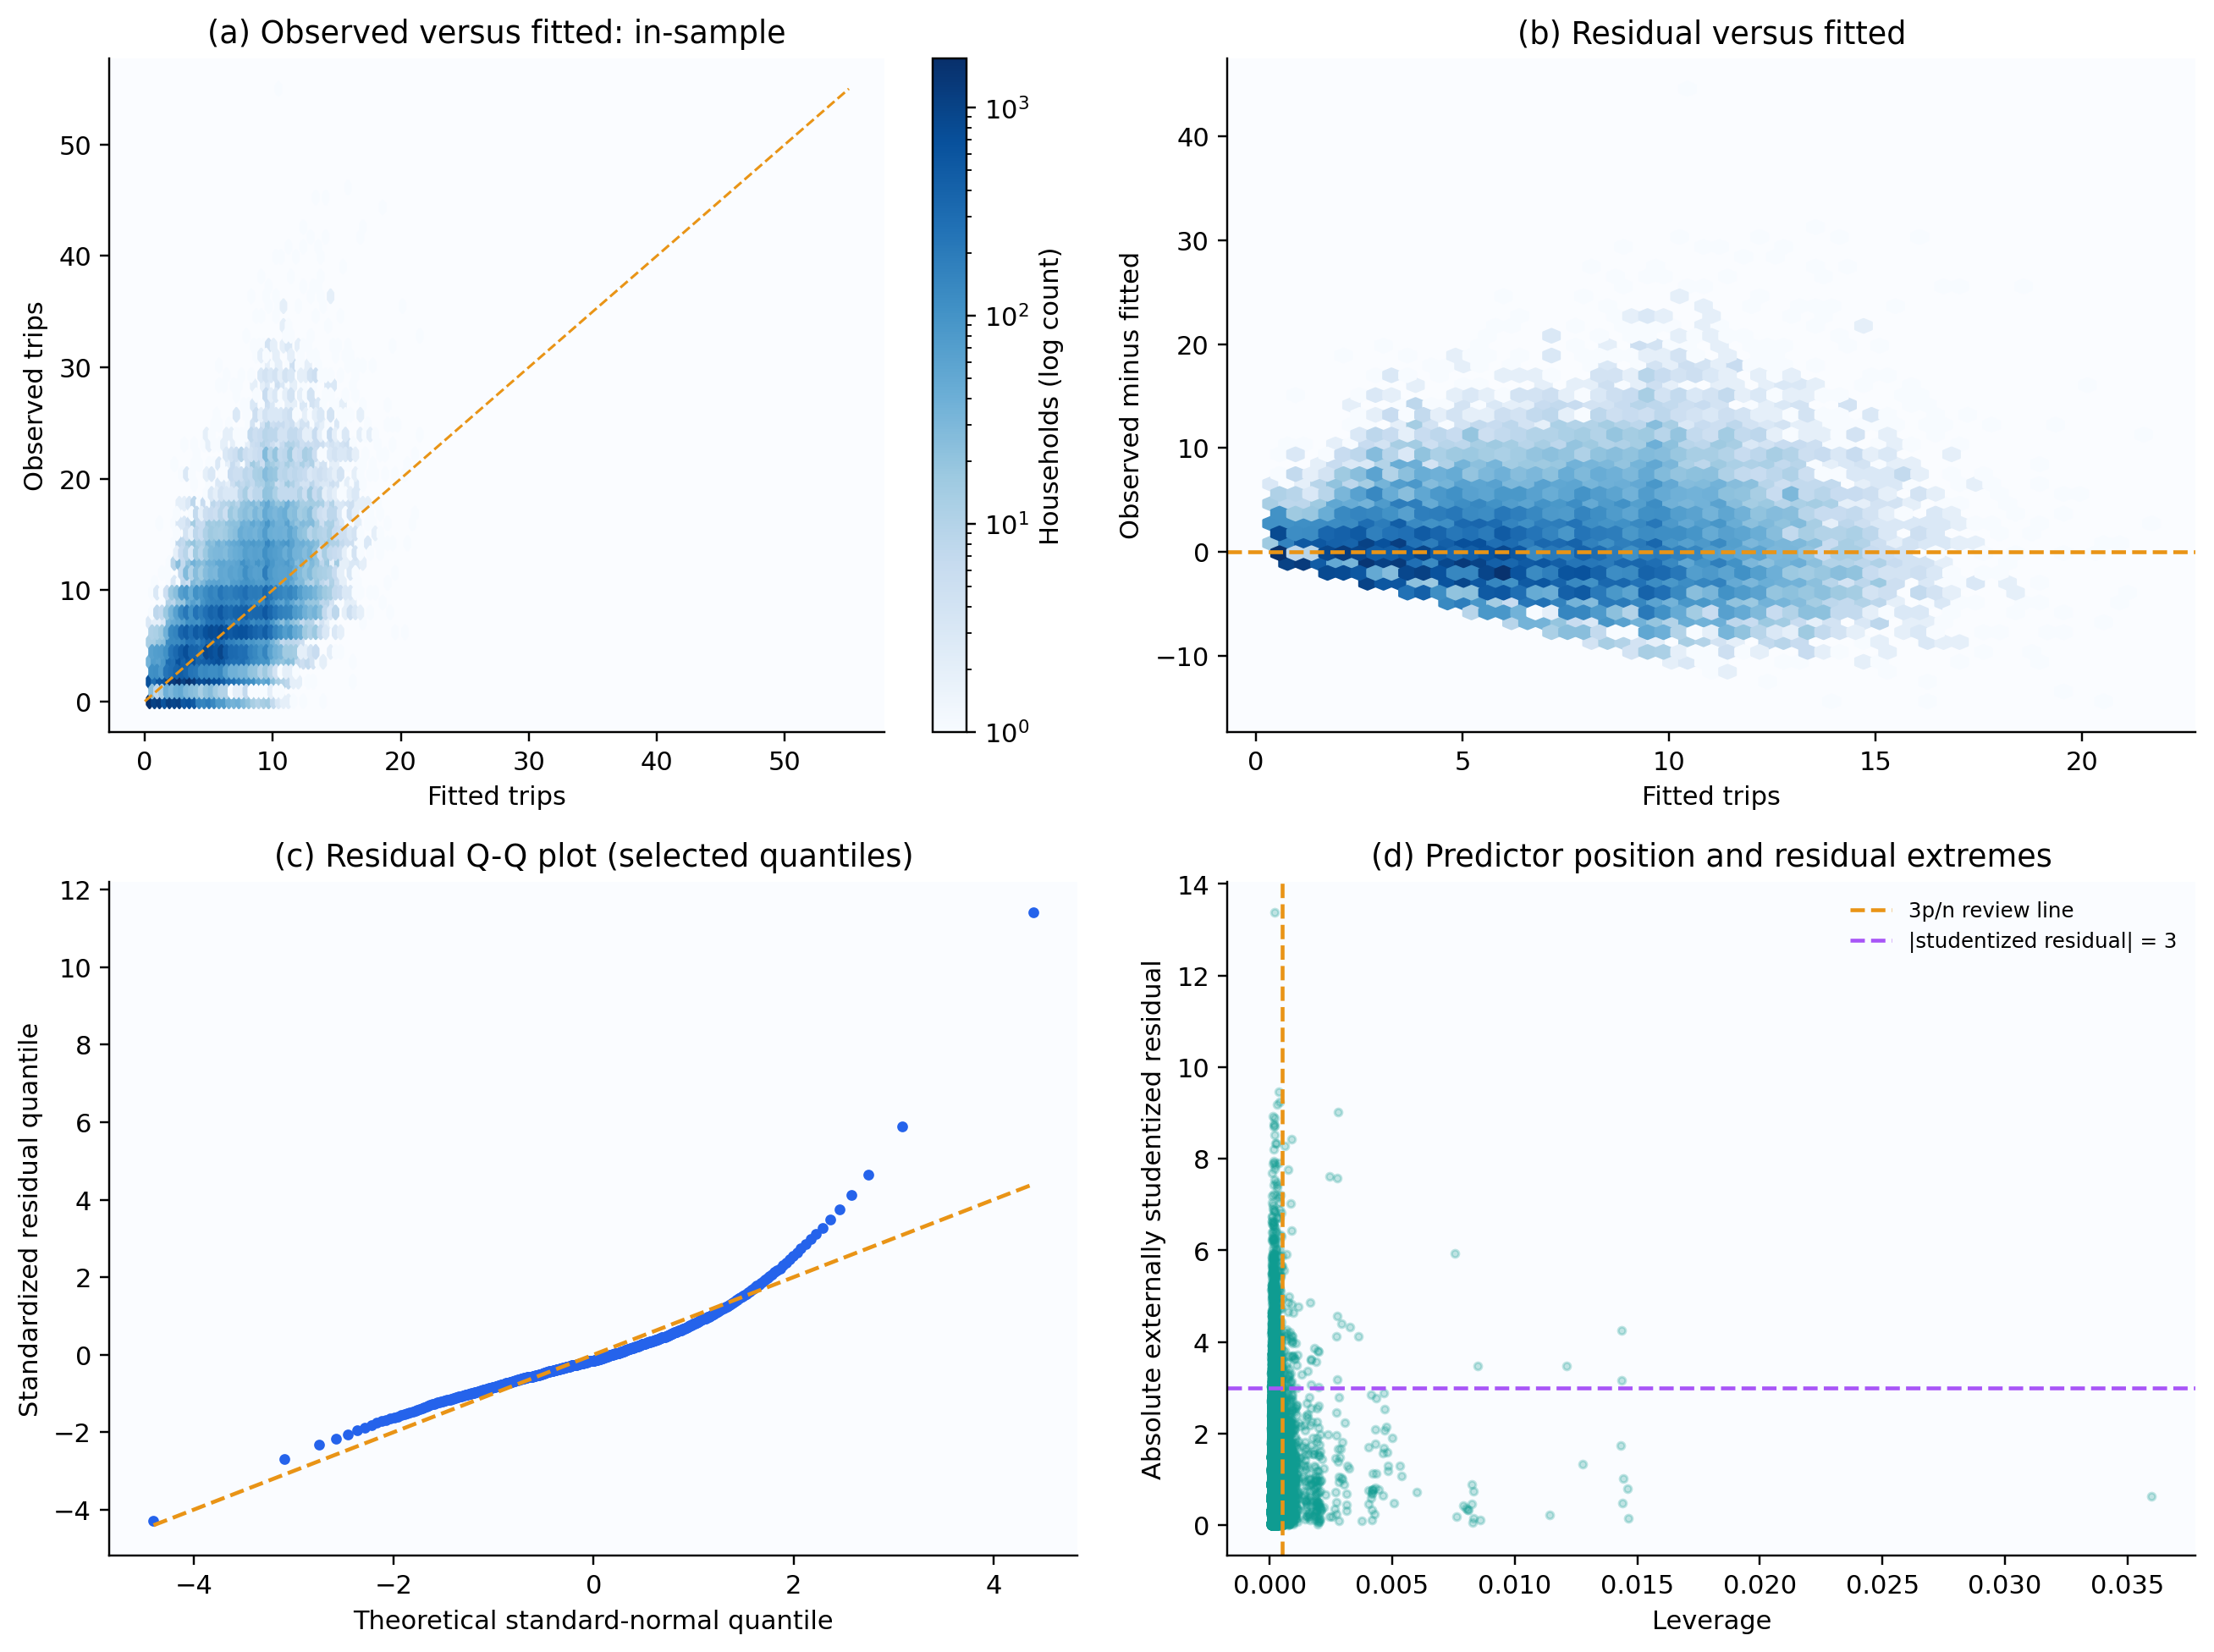

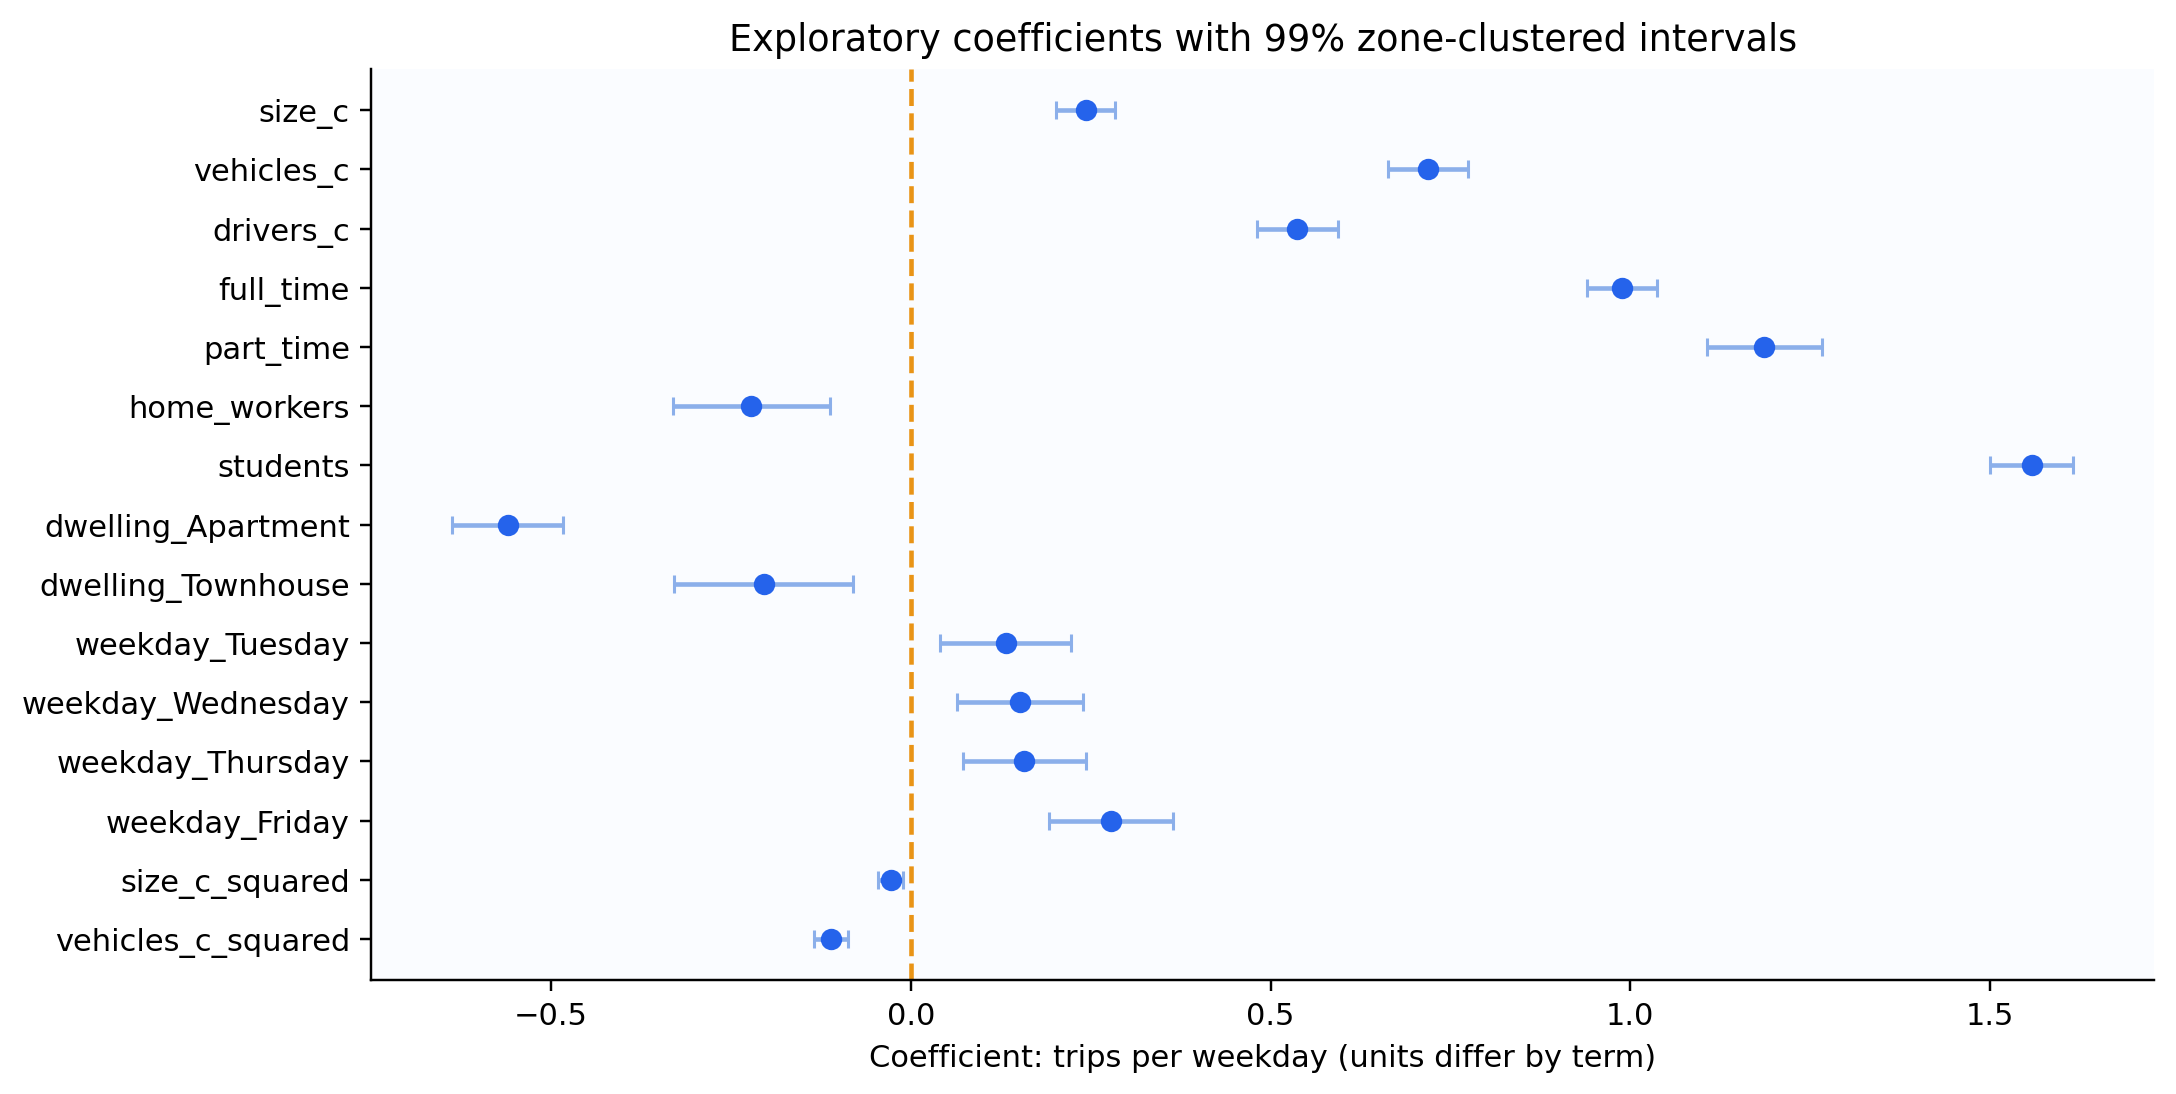

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
hb = axes[0, 0].hexbin(predicted, y, gridsize=55, mincnt=1, bins='log', cmap='Blues')
limits = [min(0, predicted.min()), max(y.max(), predicted.max())]
axes[0, 0].plot(limits, limits, '--', color=ORANGE, linewidth=1)
axes[0, 0].set(xlabel='Fitted trips', ylabel='Observed trips', title='(a) Observed versus fitted: in-sample')
fig.colorbar(hb, ax=axes[0, 0], label='Households (log count)')
axes[0, 1].hexbin(predicted, residual, gridsize=55, mincnt=1, bins='log', cmap='Blues')
axes[0, 1].axhline(0, color=ORANGE, linestyle='--')
axes[0, 1].set(xlabel='Fitted trips', ylabel='Observed minus fitted', title='(b) Residual versus fitted')
probabilities = np.unique(np.r_[.5 / N, np.linspace(.001, .999, 499), 1 - .5 / N])
normal_quantiles = stats.norm.ppf(probabilities)
standardized_residual = residual / np.sqrt(selected_ols.mse_resid)
axes[1, 0].scatter(normal_quantiles, np.quantile(standardized_residual, probabilities), s=10, color=BLUE)
axes[1, 0].plot([normal_quantiles.min(), normal_quantiles.max()],
                [normal_quantiles.min(), normal_quantiles.max()], '--', color=ORANGE)
axes[1, 0].set(xlabel='Theoretical standard-normal quantile', ylabel='Standardized residual quantile',
               title='(c) Residual Q-Q plot (selected quantiles)')
axes[1, 1].scatter(leverage, np.abs(studentized_external), s=8, alpha=.25, color=TEAL)
axes[1, 1].axvline(3 * P / N, color=ORANGE, linestyle='--', label='3p/n review line')
axes[1, 1].axhline(3, color='#A855F7', linestyle='--', label='|studentized residual| = 3')
axes[1, 1].set(xlabel='Leverage', ylabel='Absolute externally studentized residual',
               title='(d) Predictor position and residual extremes')
axes[1, 1].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, 'Trial_01_fit_and_residuals')

fig, ax = plt.subplots(figsize=(10, max(5, .34 * (len(coefficients) - 1))))
plot_coefficients = coefficients.loc[coefficients['column'].ne('Intercept')].iloc[::-1]
positions = np.arange(len(plot_coefficients))
ax.errorbar(plot_coefficients['estimate'], positions,
    xerr=np.vstack([plot_coefficients['estimate'] - plot_coefficients['CI99_lower_zone_clustered'],
                    plot_coefficients['CI99_upper_zone_clustered'] - plot_coefficients['estimate']]),
    fmt='o', color=BLUE, ecolor='#8BAFEA', capsize=3)
ax.axvline(0, color=ORANGE, linestyle='--')
ax.set_yticks(positions, plot_coefficients['column'])
ax.set(xlabel='Coefficient: trips per weekday (units differ by term)',
        title='Exploratory coefficients with 99% zone-clustered intervals')
fig.tight_layout()
save_figure(fig, 'Trial_02_coefficients')

## 7. Household groups and traffic-zone agreement

Metrics here describe the same estimation observations. Mean prediction error is predicted minus observed. No predictions are clipped, including negative values. Sample zone sums and expansion-weighted zone totals are shown separately; expansion is applied identically to observed and predicted trips. These are not held-out forecasts or comparisons against the cross-classification model yet.

,grouping,level,n,observed_mean_trips,predicted_mean_trips,MAE_in_sample,RMSE_in_sample,mean_prediction_error_pred_minus_obs,negative_predictions_n
0,Household size (5+),4,17463,8.3081,8.3289,3.1116,4.1722,0.0208,0
1,Household size (5+),2,28809,4.3551,4.2710,2.1491,2.8406,-0.0841,0
2,Household size (5+),3,17466,6.3997,6.4395,2.5177,3.3380,0.0398,0
3,Household size (5+),5+,10333,10.1639,10.1653,3.7036,4.9639,0.0014,0
4,Household size (5+),1,19194,2.0286,2.0989,1.2732,1.6704,0.0703,0
5,Vehicles (4+),2,31136,7.3260,7.2991,2.8998,3.9449,-0.0269,0
6,Vehicles (4+),1,38365,4.8507,4.8365,2.2425,3.0584,-0.0142,0
7,Vehicles (4+),0,15291,2.3446,2.3800,1.2927,1.7326,0.0354,0
8,Vehicles (4+),3,6591,8.7322,8.8570,3.1198,4.1173,0.1247,0
9,Vehicles (4+),4+,1882,9.9277,9.9384,3.3371,4.5047,0.0107,0


,evaluation,zones,MAE,RMSE,mean_prediction_error_pred_minus_obs,status
0,Sample zone totals,1179,30.5359,44.9426,-0.0000,In-sample zone agreement
1,Expansion-weighted zone totals,1179,590.6960,875.2988,7.7505,In-sample zone agreement


,evaluation,observed_mean,predicted_mean,MAE,RMSE,mean_prediction_error
0,Unweighted households,5.6429,5.6429,2.3903,3.3381,-0.0000
1,Expansion-weighted households; coefficients still unweighted OLS,5.6399,5.6449,2.3870,3.3334,0.0051


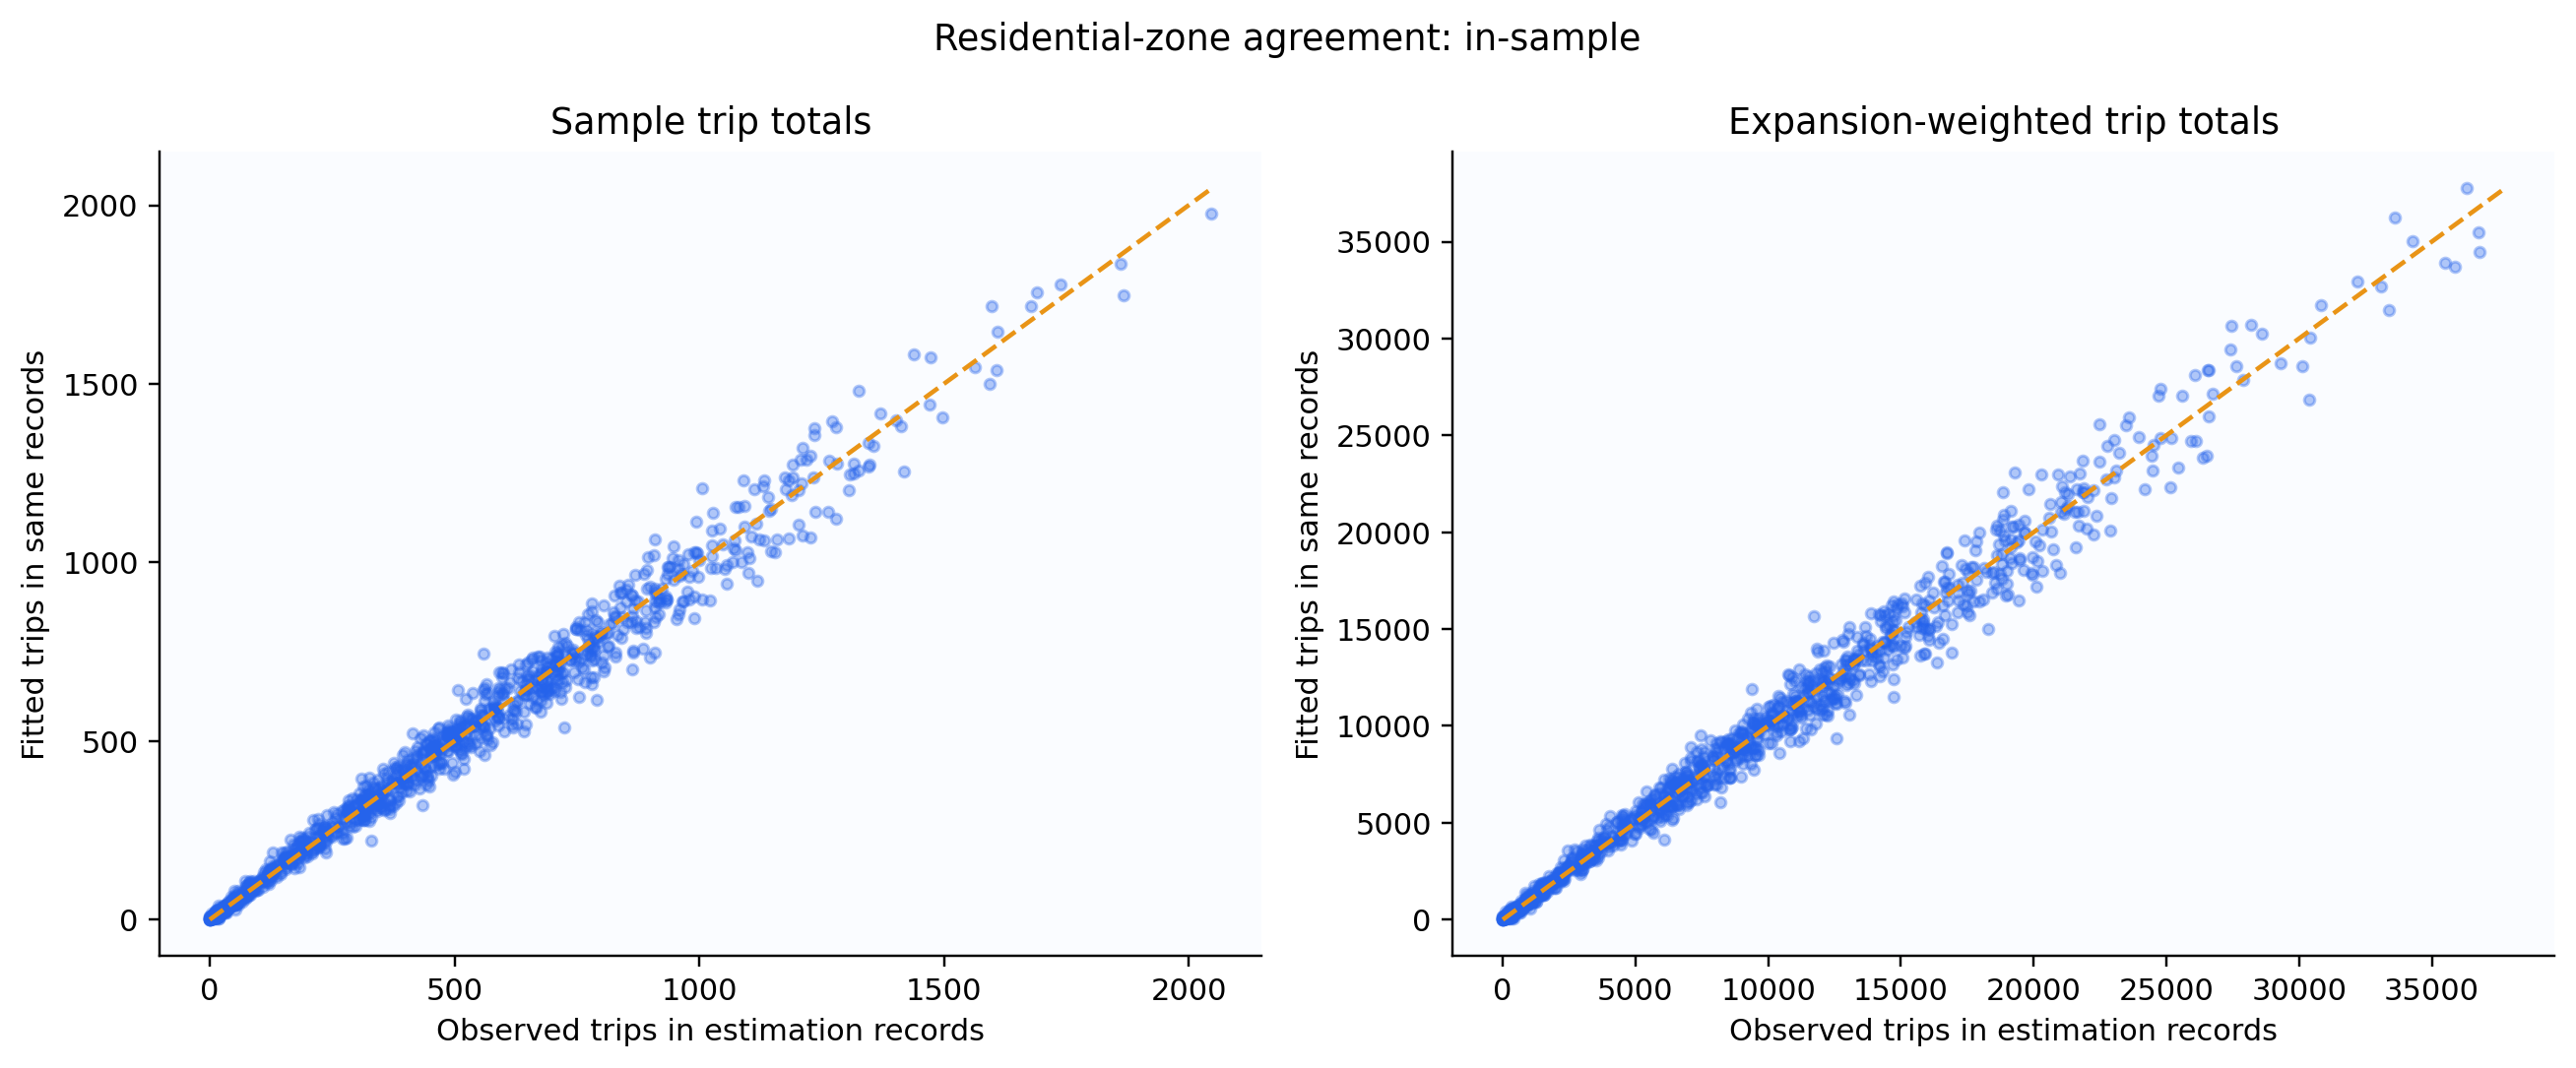

In [9]:
group_rows = []
group_definitions = {
    'Household size (5+)': trial['nperson'].clip(upper=5).astype(str).where(trial['nperson'].lt(5), '5+'),
    'Vehicles (4+)': trial['nvehicle'].clip(upper=4).astype(str).where(trial['nvehicle'].lt(4), '4+'),
    'Dwelling': trial['dwelling'], 'Weekday': trial['weekday'], 'Region': trial['region'],
}
for variable, grouping in group_definitions.items():
    for level in grouping.unique():
        mask = grouping.eq(level).to_numpy()
        error = predicted[mask] - y[mask]
        group_rows.append({'grouping': variable, 'level': str(level), 'n': int(mask.sum()),
            'observed_mean_trips': y[mask].mean(), 'predicted_mean_trips': predicted[mask].mean(),
            'MAE_in_sample': np.abs(error).mean(), 'RMSE_in_sample': np.sqrt(np.mean(error ** 2)),
            'mean_prediction_error_pred_minus_obs': error.mean(),
            'negative_predictions_n': int((predicted[mask] < 0).sum())})
group_performance = save_table('TM14_household_group_performance', pd.DataFrame(group_rows))
zone_data = pd.DataFrame({'zone': zones, 'observed': y, 'predicted': predicted,
    'expanded_observed': weights * y, 'expanded_predicted': weights * predicted,
    'expansion_weight': weights})
zone_performance = zone_data.groupby('zone').agg(
    households=('observed', 'size'), observed_sample_trips=('observed', 'sum'),
    predicted_sample_trips=('predicted', 'sum'), expanded_observed_trips=('expanded_observed', 'sum'),
    expanded_predicted_trips=('expanded_predicted', 'sum'), expanded_households=('expansion_weight', 'sum')).reset_index()
zone_performance['sample_prediction_error'] = zone_performance['predicted_sample_trips'] - zone_performance['observed_sample_trips']
zone_performance['expanded_prediction_error'] = zone_performance['expanded_predicted_trips'] - zone_performance['expanded_observed_trips']
save_table('TM15_zone_performance', zone_performance)
zone_summary_rows = []
for label, col in [('Sample zone totals', 'sample_prediction_error'), ('Expansion-weighted zone totals', 'expanded_prediction_error')]:
    error = zone_performance[col].to_numpy()
    zone_summary_rows.append({'evaluation': label, 'zones': len(error),
        'MAE': np.abs(error).mean(), 'RMSE': np.sqrt(np.mean(error ** 2)),
        'mean_prediction_error_pred_minus_obs': error.mean(), 'status': 'In-sample zone agreement'})
zone_summary = save_table('TM16_zone_summary', pd.DataFrame(zone_summary_rows))
overall_weight_sensitivity = save_table('TM17_expansion_weighted_evaluation', pd.DataFrame([
    {'evaluation': 'Unweighted households', 'observed_mean': y.mean(), 'predicted_mean': predicted.mean(),
     'MAE': np.abs(predicted - y).mean(), 'RMSE': np.sqrt(np.mean((predicted - y) ** 2)),
     'mean_prediction_error': (predicted - y).mean()},
    {'evaluation': 'Expansion-weighted households; coefficients still unweighted OLS',
     'observed_mean': np.average(y, weights=weights), 'predicted_mean': np.average(predicted, weights=weights),
     'MAE': np.average(np.abs(predicted - y), weights=weights),
     'RMSE': np.sqrt(np.average((predicted - y) ** 2, weights=weights)),
     'mean_prediction_error': np.average(predicted - y, weights=weights)},
]))
display(group_performance.round(4))
display(zone_summary.round(4))
display(overall_weight_sensitivity.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, observed_col, predicted_col, title in [
    (axes[0], 'observed_sample_trips', 'predicted_sample_trips', 'Sample trip totals'),
    (axes[1], 'expanded_observed_trips', 'expanded_predicted_trips', 'Expansion-weighted trip totals')]:
    ax.scatter(zone_performance[observed_col], zone_performance[predicted_col], s=12, alpha=.35, color=BLUE)
    largest = max(zone_performance[observed_col].max(), zone_performance[predicted_col].max())
    ax.plot([0, largest], [0, largest], '--', color=ORANGE)
    ax.set(xlabel='Observed trips in estimation records', ylabel='Fitted trips in same records', title=title)
fig.suptitle('Residential-zone agreement: in-sample')
fig.tight_layout()
save_figure(fig, 'Trial_03_zone_agreement')

## 8. Readable findings and reproducibility checks

The automatically generated report below states what the search actually found, its effect choices and removals, and limitations. Earlier source data and EDA outputs are preserved. Run this notebook top to bottom from the project root in geo_env. No helper script in the chat folder is required by the notebook.

In [10]:
def markdown_table(frame):
    frame = frame.copy()
    for col in frame.columns:
        if col in ['p_clustered', 'p_classical', 'p_zone_clustered', 'dropped_effect_p_clustered']:
            frame[col] = frame[col].map(format_pvalue)
        elif pd.api.types.is_numeric_dtype(frame[col]):
            frame[col] = frame[col].map(lambda value: '' if pd.isna(value) else f'{value:.7g}')
    frame = frame.astype(object).where(frame.notna(), '')
    lines = ['| ' + ' | '.join(map(str, frame.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    lines += ['| ' + ' | '.join(str(v).replace('|', '/').replace('\n', ' ') for v in row) + ' |'
              for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines)

chosen_stats = evaluate(chosen_effects)['stats']
primary_path = paths.loc[paths['family'].eq(chosen_family) & paths['rule'].eq('p01')]
removed_primary = primary_path.loc[primary_path['action'].eq('remove'), 'dropped_effect'].tolist()
same_primary = comparison.loc[comparison['effects'].eq(' + '.join(chosen_effects))]
search_summary = comparison[['family', 'rule', 'steps_removed', 'parameters', 'adjusted_r_squared',
    'rmse_in_sample', 'mae_in_sample', 'aic', 'bic', 'p01_satisfied_for_removable_effects']].copy()
search_summary = search_summary.round(5)
interpretation_lines = []
for row in coefficients.itertuples():
    if row.column.startswith('dwelling_'):
        interpretation_lines.append(f'- {row.column.split("_", 1)[1]} versus House: {row.estimate:+.3f} adjusted trips per weekday, 99% clustered interval [{row.CI99_lower_zone_clustered:+.3f}, {row.CI99_upper_zone_clustered:+.3f}], holding included covariates fixed.')
    elif row.column.startswith('weekday_'):
        interpretation_lines.append(f'- {row.column.split("_", 1)[1]} versus Monday: {row.estimate:+.3f} adjusted trips per weekday, holding included covariates fixed.')
    elif row.column.startswith('region_'):
        interpretation_lines.append(f'- {row.column.split("_", 1)[1]} versus Toronto: {row.estimate:+.3f} adjusted trips per weekday, holding included covariates fixed.')
if 'size_squared' in chosen_effects:
    interpretation_lines.append('- With a retained size quadratic, the change for one additional resident varies with size. For the size-only polynomial component at size s it is b_size + b_size_squared * [2(s-3)+1]; add any retained size-interaction contribution.')
if 'vehicles_squared' in chosen_effects:
    interpretation_lines.append('- With a retained vehicle quadratic, the change for one additional vehicle at v is b_vehicles + b_vehicles_squared * [2(v-1)+1], plus any retained size-by-vehicle interaction contribution.')
if 'size_by_drivers' in chosen_effects:
    interpretation_lines.append('- The size-by-driver interaction makes the size slope depend on licensed drivers and the driver slope depend on household size. Main effects are referenced to size 3 and licensed drivers 2.')
if 'size_by_vehicles' in chosen_effects:
    interpretation_lines.append('- The size-by-vehicle interaction makes the size slope depend on vehicles and vice versa. Main effects are referenced to size 3 and vehicles 1.')

report = f'''# Trial mode: regression search results

## Data and agreed exclusions

The notebook reads inputs/households.xlsx, sheet {SHEET}, named fields B:P, and creates an independent working copy. All source values and files remain intact. Recorded vehicles >={HIGH_VEHICLE_CUTOFF} remove {int(working['excluded_high_vehicle'].sum())} households, and dwelling code 9 removes {int(working['excluded_unknown_dwelling'].sum())}, with {int((working['excluded_high_vehicle'] & working['excluded_unknown_dwelling']).sum())} overlapping households. The fixed estimation sample has {N:,} households in {N_ZONES:,} residential zones. It retains {int(trial['nhhldtrip'].eq(0).sum()):,} zero-trip households. Excluded records and reasons are saved in intermediaries/trial_mode/excluded_households.csv; the actual estimation data are households_trial.csv in that folder.

Numeric vehicle 99 is source-documented and is removed under the requested outlier policy, not converted to missing. The main EDA still describes the full source sample. No other row-exclusion rule was introduced.

## What was searched

Five starting families cover separate employment counts, total workers, size/vehicle quadratics, size-by-licensed-driver interaction, and size-by-vehicle interaction. Each has a p<0.01 backward path, a separate AIC-improving path, and a separate BIC-improving path. There are {len(comparison)} terminal comparisons and {len(MODEL_CACHE)} unique predictor designs evaluated including benchmarks. The three rules can converge to identical models. This is a defined backward search, not an exhaustive search of all possible models.

Household size remains as a prespecified core variable. Categorical factors are tested and removed as blocks, and interaction/quadratic hierarchy is preserved. workers never appears together with nempft/nemppt. Reference categories are House, Monday, and Toronto. Numeric centers are size 3, vehicles 1, and licensed drivers 2. No train/test split or cross-validation is performed.

Selection uses whole-effect F tests with covariance clustered by traffic zone, with denominator degrees of freedom {N_ZONES - 1}. The p<0.01 requirement applies to removable whole effects, not every individual indicator coefficient. Classical p-values are recorded separately. AIC/BIC-only paths can retain terms not meeting the p rule. AIC/BIC are working Gaussian OLS comparisons on identical records and are not a full correlated-error or survey likelihood. The criterion does not account for the adaptive search.

## Primary trial result

The lowest-BIC terminal p<0.01 path starts from **{chosen_family}**. It retains:

{', '.join(chosen_effects)}.

Effects removed along that primary p-value path: {', '.join(removed_primary) if removed_primary else 'none; all removable starting effects already met the specified rule'}.

{markdown_table(primary_path[['step', 'action', 'dropped_effect', 'dropped_effect_p_clustered', 'parameters', 'aic', 'bic']])}

It has {chosen_stats['parameters']} fitted coefficients including the intercept, R-squared {chosen_stats['r_squared']:.4f}, adjusted R-squared {chosen_stats['adjusted_r_squared']:.4f}, in-sample RMSE {chosen_stats['rmse_in_sample']:.4f}, in-sample MAE {chosen_stats['mae_in_sample']:.4f}, working AIC {chosen_stats['aic']:.3f}, and BIC {chosen_stats['bic']:.3f}. Residual standard error sqrt(SSE/(n-p)) is {chosen_stats['residual_standard_error']:.4f}; prediction-error RMSE instead uses n. Mean prediction error is predicted minus observed.

{markdown_table(benchmarks[['model', 'parameters', 'r_squared', 'adjusted_r_squared', 'rmse_in_sample', 'mae_in_sample', 'negative_predictions_n']].round(5))}

## All terminal comparisons

{markdown_table(search_summary)}

## Selected effects and coefficients

{markdown_table(selected_effect_tests)}

{markdown_table(coefficients.drop(columns='interval_status'))}

These 99% intervals and conventional p-values are exploratory and conditional on an adaptively selected model; nominal selection-adjusted coverage is not claimed. Extremely small p-values are printed as <1e-300 rather than an exact zero; CSV zeros can reflect numerical underflow. Substantive interpretation and practical magnitudes matter with this sample size. Estimated associations are not causal effects.

{chr(10).join(interpretation_lines)}

## Diagnostics and limits

There are {int((predicted < 0).sum()):,} negative fitted trip counts; predictions were not clipped. The maximum classical Cook distance is {cook.max():.5f}; {int((cook > 1).sum())} records exceed 1, and {int((cook > 4 / N).sum())} exceed the large-sample 4/n review marker. There are {int((np.abs(studentized_external) > 3).sum())} absolute externally studentized residuals above 3. These markers do not delete additional observations. The largest column VIF is {vif_values.max():.3f}; indicator-column VIFs are not generalized factor VIFs. Quadratic/interaction columns can share information with their supporting main effects.

Residual plots, Q-Q quantiles, and household group results must be inspected. The Koenker BP nominal p-value is {format_pvalue(bp_lm_p)}, a screen that is not adjusted for within-zone dependence. Primary uncertainty is zone-clustered. Classical influence measures are individual-case sensitivity diagnostics, not full cluster/survey influence calculations. Count outcomes and skewed residuals do not by themselves forbid OLS, but nonlinear misspecification, heteroskedasticity, heavy tails, negative predictions, and coefficient stability constrain interpretation. No model is declared a validated final forecasting model.

## Household groups and zones

{markdown_table(group_performance.round(4))}

{markdown_table(zone_summary.round(4))}

{markdown_table(overall_weight_sensitivity.round(4))}

Zone results use observed and fitted trips over the same estimation records. Sample totals and expansion-weighted totals are distinct; expf is applied identically to observed and predicted values. Coefficients are unweighted OLS. This is in-sample agreement, not held-out accuracy. A fair later comparison with cross-classification must use the same eligible records and weighting conventions.

## Reproduction and outputs

Run trial mode.ipynb top to bottom from the project root using geo_env (or an environment satisfying requirements.txt). The notebook is self-contained and does not import scripts from intermediaries/chat. TM00 records package versions. TM04-TM06 record every reduction step, whole-effect test, and information-criterion deletion alternative. TM07 compares terminal models; TM08-TM13 provide effects, coefficients, benchmarks, and diagnostics; TM14-TM17 give household/zone results. Household predictions are saved in intermediaries/trial_mode/selected_model_household_predictions.csv. selected_trial_model.json records coefficients, centers, references, criteria, row IDs hash, and source workbook hash.

Source workbook SHA256: {SOURCE_SHA256}

Estimation-row ID SHA256: {row_id_hash}

Sources: [JMP variable selection](https://www.jmp.com/en/statistics-knowledge-portal/linear-models/what-is-multiple-regression/variable-selection), [Statsmodels clustered covariance](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html), [Statsmodels joint F tests](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.f_test.html), and the project data guide in inputs/dataguide2006_v1.pdf.
'''
(OUTPUT / 'trial_results.md').write_text(report, encoding='utf-8')
assert hashlib.sha256(WORKBOOK.read_bytes()).hexdigest() == SOURCE_SHA256
assert np.array_equal(pd.util.hash_pandas_object(raw, index=True), raw_fingerprint)
assert all(info['stats']['n'] == N for info in MODEL_CACHE.values())
assert comparison['row_id_sha256'].eq(row_id_hash).all()
assert np.isclose(zone_performance['observed_sample_trips'].sum(), y.sum())
assert np.isclose(zone_performance['predicted_sample_trips'].sum(), predicted.sum())
assert np.isclose(zone_performance['expanded_observed_trips'].sum(), np.dot(weights, y))
assert np.isclose(zone_performance['expanded_predicted_trips'].sum(), np.dot(weights, predicted))
assert np.isclose(coefficients['estimate'].to_numpy() @ selected_ols.model.exog.T, predicted).all()
print('Saved final_outputs/trial_mode/trial_results.md and selected_trial_model.json.')
print('Source preservation, fixed-sample comparisons, and aggregation checks passed.')
display(comparison.loc[comparison['selected_primary_trial'],
    ['family', 'rule', 'effects', 'n', 'parameters', 'adjusted_r_squared', 'rmse_in_sample', 'mae_in_sample', 'aic', 'bic']])

Saved final_outputs/trial_mode/trial_results.md and selected_trial_model.json.
Source preservation, fixed-sample comparisons, and aggregation checks passed.


,family,rule,effects,n,parameters,adjusted_r_squared,rmse_in_sample,mae_in_sample,aic,bic
1,Size and vehicle curvature,p01,size + vehicles + drivers + full_time + part_time + home_workers + students + dwelling + weekday...,93265,16,0.464563,3.338069,2.39031,489548.457256,489699.548459
